| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_1_Neural_Networks.ipynb) | [⏩](../12_DEEP_LEARNING/12_3_Deep_Learning_matematico.ipynb) |

# 12.2 Arquitecturas: localidad, secuencias, atención y simetrías

**Objetivo del cuaderno.** entender qué estructura aporta MLP, CNN, redes recurrentes, residuales y atención; aprender un mapa local de campos con una CNN

**Antes de empezar:** redes neuronales, matrices, convolución y series temporales. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
import torch
from torch import nn
torch.manual_seed(42)
torch.set_num_threads(1)
print('PyTorch:', torch.__version__, '| dispositivo: CPU')

PyTorch: 2.14.1+cpu | dispositivo: CPU


## 1. La arquitectura expresa cómo se relacionan los datos

Un MLP recibe un vector y conecta cada entrada con muchas unidades. Una CNN comparte un filtro entre posiciones. Una red recurrente comparte una regla entre tiempos. Atención calcula interacciones según contenido. Estas elecciones no son solo ingeniería: introducen supuestos sobre estructura, invariancia y escalas.

Un campo sobre una malla no equivale a una tabla arbitraria. Localidad y simetría de traslación pueden justificar convoluciones; una geometría irregular puede justificar grafos; relaciones globales pueden motivar atención o un operador espectral. La elección debe seguir el problema y la unidad de generalización.

## 2. MLP: flexible para entradas de tamaño fijo

Una capa densa de $m$ a $p$ posiciones requiere $mp+p$ parámetros. Si aplanamos un campo de $N$ puntos, la red usual depende de esa resolución. Una entrada de coordenadas $(x,t)$ a un MLP, en cambio, representa un campo continuo punto a punto y es común en PINNs.

No confundir una red que recibe coordenadas con una red que recibe un campo completo. La primera representa una función particular; la segunda puede aprender un mapa entre funciones o entre datos discretizados, dependiendo del entrenamiento.

## 3. CNN: filtros compartidos y localidad

Una convolución 1D aplica, simplificando índices,

$$h_j^{out}=\sigma\left(b+\sum_{q=-r}^{r}w_qh_{j+q}^{in}\right).$$

El mismo filtro $w$ se usa en todos los puntos. Una capa con $c_{in}$ canales, $c_{out}$ filtros y ancho $k$ tiene $c_{out}c_{in}k+c_{out}$ parámetros, independiente del número de posiciones. Las condiciones de borde del padding importan: ceros, reflexión o periodicidad implican supuestos distintos.

## 4. Experimento científico local: un mapa difusivo discreto

Aprendemos la transformación periódica $v_j=u_j+\alpha(u_{j-1}-2u_j+u_{j+1})$, con $\alpha=0.18$. Es un paso de Euler de una difusión en una malla si $\alpha=\kappa\Delta t/\Delta x^2$. Cumple una condición de estabilidad $0\le\alpha\le1/2$ en esta discretización 1D.

La transformación tiene un filtro exacto $[\alpha,1-2\alpha,\alpha]$, pero permitimos que una CNN lineal lo aprenda de campos. Separamos campos completos en entrenamiento, validación y prueba. No mezclamos posiciones de un mismo campo entre conjuntos.

CNN parámetros: 3
Densa parámetros: 4096
Filtro aprendido: [0.18 0.64 0.18]
Filtro exacto: [0.18, 0.64, 0.18]


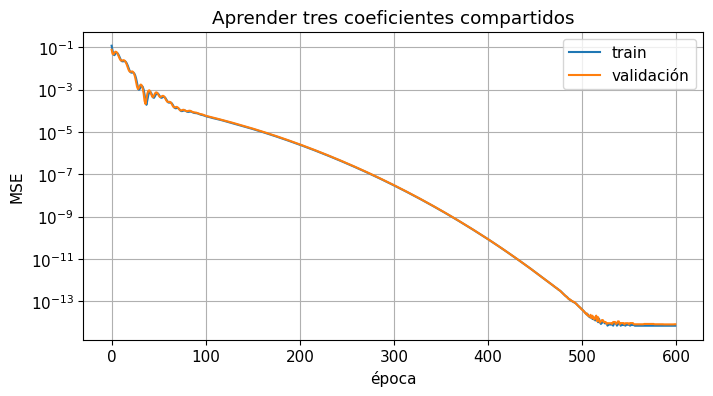

In [2]:
N=64;n_fields=120;alpha=0.18
space=np.arange(N)/N
amplitudes=rng.normal(size=(n_fields,4))
phases=rng.uniform(0,2*np.pi,(n_fields,4))
fields=np.zeros((n_fields,N))
for j in range(4):fields+=amplitudes[:,j,None]*np.sin(2*np.pi*(j+1)*space[None,:]+phases[:,j,None])
fields+=rng.normal(0,0.15,fields.shape)
target=fields+alpha*(np.roll(fields,1,axis=1)-2*fields+np.roll(fields,-1,axis=1))
U=torch.tensor(fields[:,None,:],dtype=torch.float32);V=torch.tensor(target[:,None,:],dtype=torch.float32)
train=slice(0,75);validation=slice(75,95);test=slice(95,120)
cnn=nn.Conv1d(1,1,kernel_size=3,padding=1,padding_mode='circular',bias=False)
dense=nn.Linear(N,N,bias=False)
print('CNN parámetros:',sum(p.numel() for p in cnn.parameters()))
print('Densa parámetros:',sum(p.numel() for p in dense.parameters()))
optimizer=torch.optim.Adam(cnn.parameters(),lr=0.03)
losses=[];val_losses=[];best=float('inf');best_weights=None
for epoch in range(600):
    optimizer.zero_grad();loss=nn.functional.mse_loss(cnn(U[train]),V[train]);loss.backward();optimizer.step()
    with torch.no_grad():vl=nn.functional.mse_loss(cnn(U[validation]),V[validation]).item()
    losses.append(loss.item());val_losses.append(vl)
    if vl<best:best=vl;best_weights=cnn.weight.detach().clone()
with torch.no_grad():cnn.weight.copy_(best_weights)
plt.semilogy(losses,label='train');plt.semilogy(val_losses,label='validación')
plt.xlabel('época');plt.ylabel('MSE');plt.title('Aprender tres coeficientes compartidos');plt.legend();plt.show()
print('Filtro aprendido:',cnn.weight.detach().numpy().ravel())
print('Filtro exacto:',[alpha,1-2*alpha,alpha])

**Interpretación.** La CNN tiene tres parámetros frente a $N^2$ en una capa densa. Esto coincide con la localidad y homogeneidad espacial del mapa. No demuestra que toda PDE se represente con tres coeficientes; aquí elegimos una transformación exacta muy sencilla para verificar qué aprende la arquitectura.

## 5. Predicciones de campos reservados

El filtro compartido permite evaluar todas las posiciones. La prueba se hace sobre campos nunca utilizados al actualizar pesos o seleccionar época. Además del error puntual, comprobamos conservación de la suma y que el paso no aumenta norma en esta familia.

RMSE test: 7.885188376723846e-08
Error máximo en suma: 1.5584315997685394e-06
Suma filtro CNN: 1.0


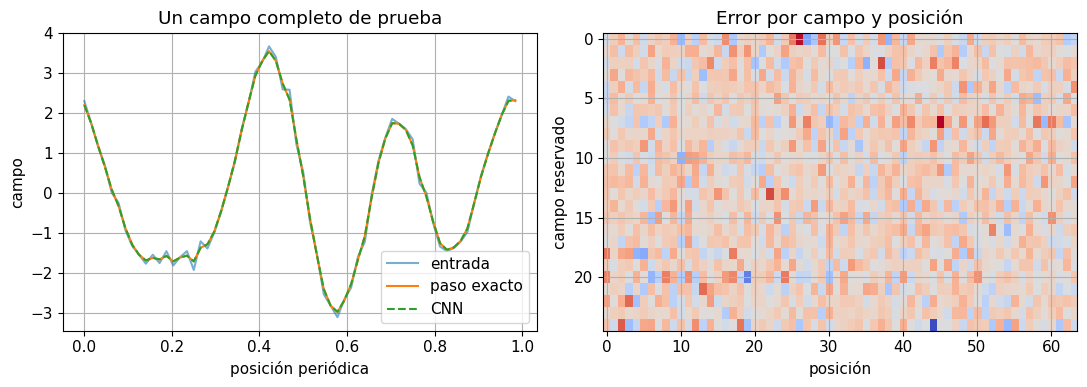

In [3]:
with torch.no_grad():prediction=cnn(U[test]).numpy()[:,0,:]
true_test=target[test];u_test=fields[test]
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(space,u_test[0],alpha=0.6,label='entrada');ax[0].plot(space,true_test[0],label='paso exacto')
ax[0].plot(space,prediction[0],'--',label='CNN');ax[0].set(xlabel='posición periódica',ylabel='campo',title='Un campo completo de prueba');ax[0].legend()
ax[1].imshow(prediction-true_test,aspect='auto',cmap='coolwarm');ax[1].set(xlabel='posición',ylabel='campo reservado',title='Error por campo y posición')
plt.tight_layout();plt.show()
print('RMSE test:',np.sqrt(np.mean((prediction-true_test)**2)))
print('Error máximo en suma:',np.max(np.abs(prediction.sum(axis=1)-u_test.sum(axis=1))))
print('Suma filtro CNN:',cnn.weight.detach().numpy().sum())

## 6. Equivarianza, conservación y estabilidad

Equivarianza a traslación significa $F(Tu)=TF(u)$. Una CNN con filtro compartido y padding circular posee esta propiedad sobre desplazamientos enteros periódicos. La conservación de suma requiere además que la suma de coeficientes sea uno en esta capa lineal. Equivarianza no implica conservación por sí sola.

El mapa difusivo exacto atenúa frecuencias según $G(q)=1-4\alpha\sin^2(q/2)$. Una red con error pequeño en un paso puede ser inestable al repetirse muchas veces si sus factores amplifican alguna frecuencia. Debemos evaluar rollouts, no solamente un paso.

## 7. Prueba de simetría y evolución repetida

Residuo equivarianza: 0.0


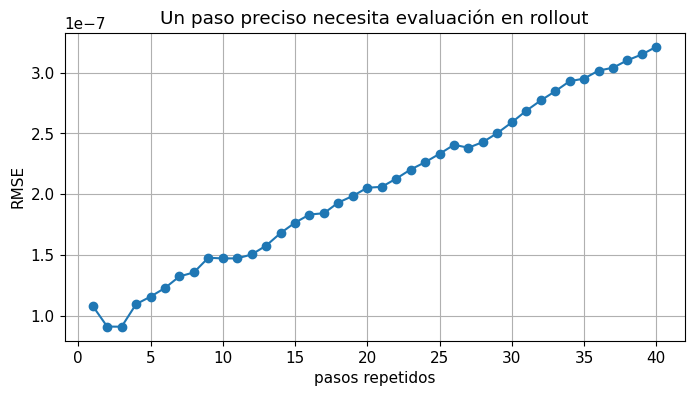

In [4]:
with torch.no_grad():
    shifted=torch.roll(U[test],shifts=7,dims=-1)
    symmetry_error=(cnn(shifted)-torch.roll(cnn(U[test]),shifts=7,dims=-1)).abs().max().item()
state_true=u_test[0].copy();state_net=U[test][0:1].clone();rollout_errors=[]
for step in range(40):
    state_true=state_true+alpha*(np.roll(state_true,1)-2*state_true+np.roll(state_true,-1))
    with torch.no_grad():state_net=cnn(state_net)
    rollout_errors.append(np.sqrt(np.mean((state_net.numpy()[0,0]-state_true)**2)))
plt.plot(np.arange(1,41),rollout_errors,'o-');plt.xlabel('pasos repetidos');plt.ylabel('RMSE')
plt.title('Un paso preciso necesita evaluación en rollout');plt.show()
print('Residuo equivarianza:',symmetry_error)
assert symmetry_error<1e-5

## 8. Redes residuales: aprender una corrección

Una capa residual calcula $h_{l+1}=h_l+F_l(h_l)$. La conexión identidad facilita flujo de gradientes y representa una corrección respecto al estado previo. Su forma recuerda Euler $u_{n+1}=u_n+\Delta t f(u_n)$, pero una red residual arbitraria no es automáticamente un integrador físico estable.

Para evolución científica es útil aprender una corrección o término desconocido sobre un solver conocido. Aun así, las unidades de la corrección, escala temporal y estabilidad deben verificarse. Una arquitectura residual no garantiza que la energía sea positiva o conservada.

## 9. Recurrentes y memoria temporal

Una RNN aplica $h_t=\sigma(W_xx_t+W_hh_{t-1}+b)$. Reutiliza pesos en el tiempo y resume historia. LSTM y GRU añaden compuertas para regular memoria. El entrenamiento retropropaga por tiempo; secuencias largas pueden sufrir gradientes pequeños o grandes.

Si el estado físico observado no contiene toda la información de la dinámica, la memoria puede ayudar. Sin embargo, una RNN entrenada con la historia completa no debe evaluarse usando inadvertidamente valores futuros. Divide cronológicamente o por trayectorias y prueba predicciones autónomas además de las condicionadas en datos reales.

## 10. Atención y relaciones globales

La atención de producto escalado calcula

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(QK^T/\sqrt{d_k})V.$$

Cada elemento agrega valores según compatibilidad de consultas y claves. La posición no se obtiene de la atención por sí sola: necesita información posicional o geométrica. La atención densa suele requerir memoria cuadrática en número de elementos.

En mallas o partículas puede representar interacciones lejanas, pero una matriz de atención no es por sí sola una explicación causal. Una máscara causal evita usar tiempos futuros cuando la tarea requiere predicción temporal.

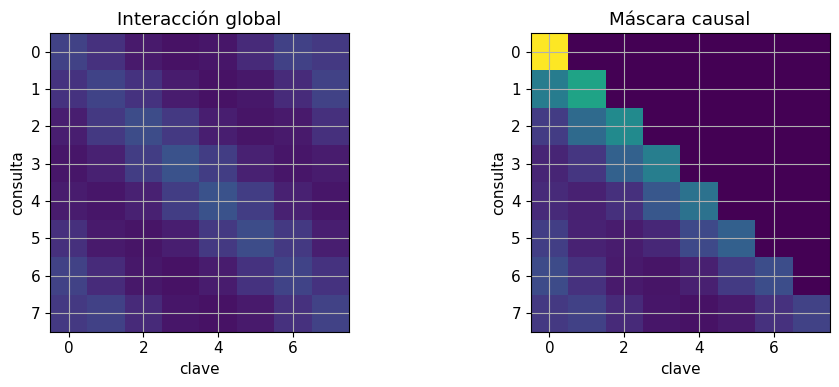

In [5]:
positions=torch.arange(8,dtype=torch.float32)[:,None]
Q=torch.cat([torch.sin(positions),torch.cos(positions)],dim=1)
K=Q.clone();V=torch.sin(positions)
attention=torch.softmax(Q@K.T/np.sqrt(2),dim=-1)
causal_mask=torch.triu(torch.ones(8,8,dtype=torch.bool),diagonal=1)
causal=torch.softmax((Q@K.T/np.sqrt(2)).masked_fill(causal_mask,float('-inf')),dim=-1)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(attention.numpy(),vmin=0,vmax=1,cmap='viridis');ax[0].set(title='Interacción global',xlabel='clave',ylabel='consulta')
ax[1].imshow(causal.numpy(),vmin=0,vmax=1,cmap='viridis');ax[1].set(title='Máscara causal',xlabel='clave',ylabel='consulta')
plt.tight_layout();plt.show()
assert torch.allclose(attention.sum(dim=1),torch.ones(8))
assert torch.all(causal[causal_mask]==0)

## 11. Resolución, grafos y operadores

La CNN puede recibir otra longitud porque comparte filtros, pero usar el mismo filtro en una malla más fina no equivale a la misma física: $\alpha=\kappa\Delta t/\Delta x^2$ cambia al cambiar $\Delta x$. Para generalizar resolución debe representarse ese cambio o aprender un operador continuo con evaluación consistente.

Redes de grafos conectan nodos según geometría o interacción; sus reglas de agregación pueden respetar permutaciones. Neural operators aprenden mapas entre funciones y buscan transferir discretizaciones bajo un diseño concreto. Ninguna arquitectura garantiza automáticamente convergencia al refinar malla.

## 12. Elegir una arquitectura para una pregunta

Para parámetros→observable de dimensión pequeña, empieza con MLP o modelos clásicos. Para campos sobre mallas regulares y procesos locales, explora CNN. Para secuencias parcialmente observadas, estudia memoria. Para geometrías irregulares, considera grafos. Para dependencias globales, atención u operadores pueden ser apropiados. Justifica elección con datos, estructura y evaluación, no con popularidad.

In [6]:
kernel=cnn.weight.detach().numpy().ravel()
q=np.linspace(0,np.pi,200)
exact_gain=1-4*alpha*np.sin(q/2)**2
learned_gain=kernel[0]*np.exp(-1j*q)+kernel[1]+kernel[2]*np.exp(1j*q)
print('Amplificación exacta máxima:',np.max(np.abs(exact_gain)))
print('Amplificación aprendida máxima:',np.max(np.abs(learned_gain)))
print('Este diagnóstico corresponde al mapa lineal periódico; no es una garantía para una CNN no lineal.')

Amplificación exacta máxima: 1.0
Amplificación aprendida máxima: 1.0000000149011612
Este diagnóstico corresponde al mapa lineal periódico; no es una garantía para una CNN no lineal.


## Síntesis y conexión con Scientific Machine Learning

La estructura de la arquitectura debe coincidir con las relaciones del problema. El experimento CNN muestra cómo localidad y pesos compartidos reducen parámetros, y cómo simetría, conservación y estabilidad son propiedades distintas. En SciML se validan campos, trayectorias, resolución y parámetros nuevos.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_1_Neural_Networks.ipynb) | [⏩](../12_DEEP_LEARNING/12_3_Deep_Learning_matematico.ipynb) |